<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/03-PyTorch-Computer-Vision/notebooks/learning/03_DL_multi_class_computer_vision_classification_DL_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# This is a DL model for a computer vision to classifiy multi-class iamges (Fashion Dataset)

### Steps:
1. Get our dataset `FashionMNIST` Test + Train
2. Create a dataloader with batching

In [1]:
# 1. Gettign out dataset (FashionMINSET)

import torchvision
import torchvision.datasets
import torchvision.transforms as transforms

train_dataset = torchvision.datasets.FashionMNIST(root="data",
                                                  train=True,
                                                  transform=transforms.ToTensor(),
                                                  download=True)

test_dataset = torchvision.datasets.FashionMNIST(root="data",
                                                  train=False,
                                                  transform=transforms.ToTensor(),
                                                  download=True)



100%|██████████| 26.4M/26.4M [00:01<00:00, 19.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 313kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.81MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.9MB/s]


In [2]:
type(train_dataset.data)

torch.Tensor

In [3]:
train_dataset.data.shape, test_dataset.data.shape

(torch.Size([60000, 28, 28]), torch.Size([10000, 28, 28]))

In [4]:
#  60000 img, with 28*28 resolution -> training

In [5]:
# See the first data element
image, label = train_dataset[0]
CLASS_NAMES = train_dataset.classes
CLASS_NAMES

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [6]:
CLASS_NAMES[label]

'Ankle boot'

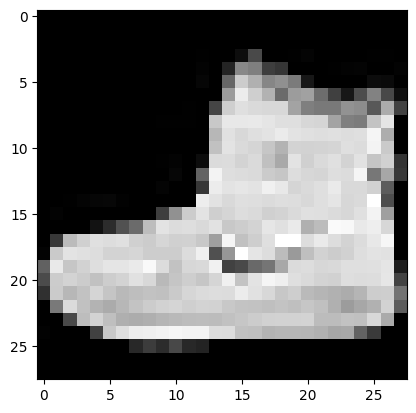

In [7]:
import matplotlib.pyplot as plt
plt.imshow(image.squeeze(), cmap="gray")

In [8]:
type(image), type(label)

(torch.Tensor, int)

In [9]:
image.shape

torch.Size([1, 28, 28])

In [10]:
# We have train/test data -> each elemnt is an iamge with 1*28*28, with number as a label

### 1.2 Prepare our dataloader -> so we can iterate it (and batch it)

In [11]:
import torch
from torch.utils.data import  DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(dataset=train_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=True
                              )
test_dataloader = DataLoader(dataset=test_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=False
                              )

print(f"Train DataLoader: {train_dataloader}")
print(f"Test DataLoader: {test_dataloader}")

Train DataLoader: <torch.utils.data.dataloader.DataLoader object at 0x7ff8943ee270>
Test DataLoader: <torch.utils.data.dataloader.DataLoader object at 0x7ff894422490>


In [12]:
train_dataloader.batch_size


32

In [13]:
train_dataloader.dataset


Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [14]:
print(f" len of train dataloader: {len(train_dataloader)} -> # of batches")
print(f" len of test dataloader: {len(test_dataloader)}")

 len of train dataloader: 1875 -> # of batches
 len of test dataloader: 313


In [15]:
# make dataloader iterable so we can iterate it
iter(train_dataloader)

In [16]:
# See the 1st element (batch) of the iterable
next(iter(train_dataloader))

[tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           ...,
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],
 
 
         [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           ...,
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],
 
 
         [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
           [0.0000

In [17]:
batch, labels = next(iter(train_dataloader))

In [18]:
batch

tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..

In [19]:
labels

tensor([3, 5, 8, 5, 5, 8, 7, 9, 9, 0, 4, 1, 0, 2, 5, 3, 0, 6, 2, 5, 7, 4, 6, 3,
        4, 5, 0, 8, 4, 2, 7, 2])

In [20]:
[color_channels, hieght, width] = batch[0].shape
hieght, width

(28, 28)

In [21]:
# 2. Create our model (linear version)
from torch import nn

class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape, output_shape, hidden_units=10):
    super().__init__()

    self.layer_Stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.Linear(in_features=hidden_units, out_features=output_shape)
    )

  def forward(self, x):
    return self.layer_Stack(x)



In [22]:
batch[0].shape

torch.Size([1, 28, 28])

In [23]:

input_shape = hieght * width
output_shape = len(CLASS_NAMES)
model_0 = FashionMNISTModelV0(input_shape=input_shape,
                              output_shape=output_shape,
                              hidden_units=10)
model_0.state_dict()

OrderedDict([('layer_Stack.1.weight',
              tensor([[-1.8787e-02, -3.6354e-03,  2.3883e-02,  ..., -1.3722e-02,
                       -9.5832e-03, -1.8959e-02],
                      [ 2.4883e-02, -1.8070e-02, -2.6396e-02,  ..., -1.7203e-02,
                       -2.3547e-02,  3.4957e-02],
                      [ 3.3352e-02,  2.2846e-02,  6.8727e-03,  ..., -3.1706e-02,
                       -1.0448e-02, -2.5332e-02],
                      ...,
                      [ 6.7882e-03, -3.2742e-03,  2.1352e-02,  ..., -3.3621e-02,
                       -3.1761e-02, -1.6902e-02],
                      [-3.3610e-02, -1.4982e-05, -3.0686e-02,  ..., -2.1715e-02,
                       -1.7732e-02, -1.3074e-03],
                      [ 2.8635e-02, -3.3719e-02,  1.6424e-02,  ..., -2.6654e-02,
                        2.3429e-02,  3.4487e-02]])),
             ('layer_Stack.1.bias',
              tensor([ 0.0062,  0.0226, -0.0127,  0.0069, -0.0120, -0.0139, -0.0084, -0.0286,
                

In [24]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 10.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [25]:
# 3. Trainign loop
import torch.optim as optim
from torchmetrics import Accuracy

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_0.parameters(),
                      lr=0.1)

accuracy_fn = Accuracy(task="multiclass", num_classes=len(CLASS_NAMES))

In [26]:
# Timer fin

from timeit import default_timer as timer

def print_total_time(start:float, end:float, device:torch.device=None):
  total_time = end - start
  print(f"Total Time {total_time}")
  return total_time


In [31]:
from tqdm.auto import tqdm

epochs = 3

for eposh in tqdm(range(epochs)):

  train_batch_loss, batch_acc = 0, 0

  model_0.train()

  for batch_num, (X, y) in enumerate(train_dataloader):
    y_logits = model_0(X)
    # y_pred = torch.argmax(y_logits)

    # We use the logits for loss
    # and the preds for accuracy

    loss = loss_fn(y_logits, y)
    train_batch_loss += loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  train_batch_loss /= len(train_dataloader)

  # Evaluation loop

  model_0.eval()
  with torch.inference_mode():
    test_batch_loss, test_batch_acc = 0, 0
    for X, y in test_dataloader:
      test_logits = model_0(X)
      test_pred = torch.argmax(test_logits, dim=1)

      test_loss = loss_fn(test_logits, y)
      test_batch_loss += test_loss

      test_batch_acc += accuracy_fn(test_pred, y)

    test_batch_loss /= len(test_dataloader)
    test_batch_acc /= len(test_dataloader)

  print(f"\nTrain loss: {train_batch_loss:.4f} | Test loss: {test_batch_loss:.4f}, Test acc: {test_batch_acc:.4f}")



  0%|          | 0/3 [00:00<?, ?it/s]


Train loss: 0.4260 | Test loss: 0.4665, Test acc: 0.8346

Train loss: 0.4232 | Test loss: 0.4661, Test acc: 0.8354

Train loss: 0.4180 | Test loss: 0.4578, Test acc: 0.8393


In [41]:
# Create one function for testing and evlauting, instead of calling both functions each eopch -> memory and class stack overhead

from tqdm.auto import tqdm


def model_testing_and_evaluation(epochs:int,
                                 model:nn.Module,
                                 train_dataloader:torch.utils.data.DataLoader,
                                 test_dataloader:torch.utils.data.DataLoader,
                                 loss_fn:nn.Module,
                                 accuracy_fn,
                                 optimizer:torch.optim.Optimizer):

  for epoch in tqdm(range(epochs)):

    model.train()

    train_loss, train_acc = 0, 0

    # Training loop
    for batch_num, (X, y) in enumerate(train_dataloader):
      y_logits = model(X)
      loss = loss_fn(y_logits, y)

      train_loss += loss
      train_acc += accuracy_fn(torch.argmax(y_logits, dim=1), y)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)

    # Testing/Evalution loop
    model.eval()
    with torch.inference_mode():
      test_loss, test_acc = 0, 0
      for X, y in test_dataloader:
        test_logits = model(X)
        test_loss += loss_fn(test_logits, y)
        test_acc += accuracy_fn(torch.argmax(test_logits, dim=1), y)

      test_loss /= len(test_dataloader)
      test_acc /= len(test_dataloader)

    print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")


In [42]:
model_testing_and_evaluation(epochs=10,
                             model=model_0,
                             train_dataloader=train_dataloader,
                             test_dataloader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             optimizer=optimizer)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 0 | Train loss: 0.4098 | Train acc: 0.8556 | Test loss: 0.4796 | Test acc: 0.8370
Epoch: 1 | Train loss: 0.4097 | Train acc: 0.8564 | Test loss: 0.5132 | Test acc: 0.8194
Epoch: 2 | Train loss: 0.4064 | Train acc: 0.8577 | Test loss: 0.4570 | Test acc: 0.8428
Epoch: 3 | Train loss: 0.4057 | Train acc: 0.8579 | Test loss: 0.4652 | Test acc: 0.8353
Epoch: 4 | Train loss: 0.4045 | Train acc: 0.8568 | Test loss: 0.4630 | Test acc: 0.8370
Epoch: 5 | Train loss: 0.4038 | Train acc: 0.8573 | Test loss: 0.4840 | Test acc: 0.8298
Epoch: 6 | Train loss: 0.4012 | Train acc: 0.8590 | Test loss: 0.4578 | Test acc: 0.8385
Epoch: 7 | Train loss: 0.4007 | Train acc: 0.8591 | Test loss: 0.4559 | Test acc: 0.8405
Epoch: 8 | Train loss: 0.4016 | Train acc: 0.8585 | Test loss: 0.4673 | Test acc: 0.8355
Epoch: 9 | Train loss: 0.3988 | Train acc: 0.8598 | Test loss: 0.4836 | Test acc: 0.8350


In [43]:
def eval_model(model:nn.Module,
               test_dataloader:torch.utils.data.DataLoader,
               loss_fn:nn.Module,
               accuracy_fn):
  model.eval()

  with torch.inference_mode():

    test_loss, test_acc = 0, 0

    for X, y in test_dataloader:

      test_logits = model(X)
      loss = loss_fn(test_logits, y)

      test_loss += loss
      test_acc += accuracy_fn(torch.argmax(test_logits, dim=1), y)

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")

In [44]:
eval_model(model=model_0,
           test_dataloader=test_dataloader,
           loss_fn=loss_fn,
           accuracy_fn=accuracy_fn)

Test loss: 0.4836 | Test acc: 0.8350
